In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import json
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = "/content/drive/MyDrive/Traffic_Sign_Project"
DATASET_DIR = "/content/traffic_sign_dataset/traffic_sign"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("TensorFlow:", tf.__version__)
print("Training directory:", TRAIN_DIR)
print("Test directory:", TEST_DIR)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Training directory: /content/traffic_sign_dataset/traffic_sign/train
Test directory: /content/traffic_sign_dataset/traffic_sign/test
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Traffic_Sign_Project/traffic_sign.zip"
EXTRACT_ROOT = "/content/traffic_sign_dataset"

assert os.path.exists(ZIP_PATH), f"ZIP not found: {ZIP_PATH}"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_ROOT)

# Locate the actual train and test folders
for root, dirs, files in os.walk(EXTRACT_ROOT):
    if "train" in dirs and "test" in dirs:
        TRAIN_DIR = os.path.join(root, "train")
        TEST_DIR = os.path.join(root, "test")
        break
else:
    raise FileNotFoundError(
        "Could not find train and test folders after extraction."
    )

print("Train folder exists:", os.path.exists(TRAIN_DIR))
print("Test folder exists:", os.path.exists(TEST_DIR))
print("Train class folders:", len(os.listdir(TRAIN_DIR)))
print("Test class folders:", len(os.listdir(TEST_DIR)))
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)

Train folder exists: True
Test folder exists: True
Train class folders: 85
Test class folders: 85
TRAIN_DIR: /content/traffic_sign_dataset/traffic_sign/train
TEST_DIR: /content/traffic_sign_dataset/traffic_sign/test


In [5]:
import os
import json
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = "/content/drive/MyDrive/Traffic_Sign_Project"
DATASET_DIR = "/content/traffic_sign_dataset/traffic_sign"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")
VALIDATION_DIR = "/content/traffic_sign_dataset/validation"

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Project folder exists:", os.path.exists(PROJECT_DIR))
print("Training folder exists:", os.path.exists(TRAIN_DIR))
print("Test folder exists:", os.path.exists(TEST_DIR))

Project folder exists: True
Training folder exists: True
Test folder exists: True


In [6]:
import random
import shutil

SOURCE_TRAIN_DIR = Path(TRAIN_DIR)
RESNET_TRAIN_DIR = Path("/content/traffic_sign_dataset/resnet_train")
VALIDATION_DIR = Path(VALIDATION_DIR)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Reuse the existing clean split if available
if not RESNET_TRAIN_DIR.exists() or not VALIDATION_DIR.exists():
    if RESNET_TRAIN_DIR.exists():
        shutil.rmtree(RESNET_TRAIN_DIR)
    if VALIDATION_DIR.exists():
        shutil.rmtree(VALIDATION_DIR)

    RESNET_TRAIN_DIR.mkdir(parents=True)
    VALIDATION_DIR.mkdir(parents=True)
    random.seed(SEED)

    for class_dir in sorted(SOURCE_TRAIN_DIR.iterdir()):
        if not class_dir.is_dir():
            continue

        images = [
            p for p in class_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        ]
        random.shuffle(images)

        if len(images) < 2:
            raise ValueError(f"Too few images in {class_dir.name}")

        val_count = max(1, round(len(images) * 0.20))
        train_images = images[val_count:]
        val_images = images[:val_count]

        train_class = RESNET_TRAIN_DIR / class_dir.name
        val_class = VALIDATION_DIR / class_dir.name
        train_class.mkdir(parents=True)
        val_class.mkdir(parents=True)

        for p in train_images:
            shutil.copy2(p, train_class / p.name)
        for p in val_images:
            shutil.copy2(p, val_class / p.name)

def count_images(folder):
    return sum(
        1 for p in Path(folder).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )

train_classes = sorted(p.name for p in RESNET_TRAIN_DIR.iterdir() if p.is_dir())
val_classes = sorted(p.name for p in VALIDATION_DIR.iterdir() if p.is_dir())
test_classes = sorted(p.name for p in Path(TEST_DIR).iterdir() if p.is_dir())

print("Training images:", count_images(RESNET_TRAIN_DIR))
print("Validation images:", count_images(VALIDATION_DIR))
print("Test images:", count_images(TEST_DIR))
print("Training classes:", len(train_classes))
print("Validation classes:", len(val_classes))
print("Test classes:", len(test_classes))
print("Class names match:", train_classes == val_classes == test_classes)

assert len(train_classes) == 85
assert train_classes == val_classes == test_classes

Training images: 3551
Validation images: 887
Test images: 1288
Training classes: 85
Validation classes: 85
Test classes: 85
Class names match: True


#EfficientNet-B0

In [7]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(RESNET_TRAIN_DIR),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(VALIDATION_DIR),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    str(TEST_DIR),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

CLASS_NAMES = train_ds.class_names

assert CLASS_NAMES == val_ds.class_names == test_ds.class_names

print("Number of classes:", len(CLASS_NAMES))
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 3551 files belonging to 85 classes.
Found 887 files belonging to 85 classes.
Found 1288 files belonging to 85 classes.
Number of classes: 85
Training batches: 111
Validation batches: 28
Test batches: 41


In [8]:
from tensorflow import keras
from tensorflow.keras import layers

base_model = keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained feature extractor initially
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

# Keras EfficientNet includes its own input rescaling
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    len(CLASS_NAMES),
    activation="softmax"
)(x)

efficientnet_model = keras.Model(
    inputs,
    outputs,
    name="EfficientNetB0_TrafficSigns"
)

efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_TrafficSigns"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 85)             │       108,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,158,456 (15.86 MB)

 Trainable params: 108,885 (425.33 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [9]:
from tensorflow import keras

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNet-B0 compiled successfully!")
print("Output classes:", efficientnet_model.output_shape[-1])
print("Total parameters:", f"{efficientnet_model.count_params():,}")
print(
    "Trainable parameters:",
    f"{sum(int(tf.size(v)) for v in efficientnet_model.trainable_variables):,}"
)

EfficientNet-B0 compiled successfully!
Output classes: 85
Total parameters: 4,158,456
Trainable parameters: 108,885


In [10]:
import os

MODEL_DIR = os.path.join(PROJECT_DIR, "models", "efficientnetb0")
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "efficientnetb0_best.keras"
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

In [11]:
history = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.2493 - loss: 3.2239
Epoch 1: val_loss improved from None to 1.62470, saving model to /content/drive/MyDrive/Traffic_Sign_Project/models/efficientnetb0/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Traffic_Sign_Project/models/efficientnetb0/efficientnetb0_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 94s 575ms/step - accuracy: 0.3717 - loss: 2.5501 - val_accuracy: 0.5772 - val_loss: 1.6247 - learning_rate: 0.0010
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.6361 - loss: 1.4302
Epoch 2: val_loss improved from 1.62470 to 1.20279, saving model to /content/drive/MyDrive/Traffic_Sign_Project/models/efficientnetb0/efficientnetb0_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Traffic_Sign_Project/models/efficientnetb0/efficientnetb0_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 37s 337ms/step - accuracy: 0.6570 - loss: 1.3456 - val_accuracy: 0.7001 - val_lo

1hr

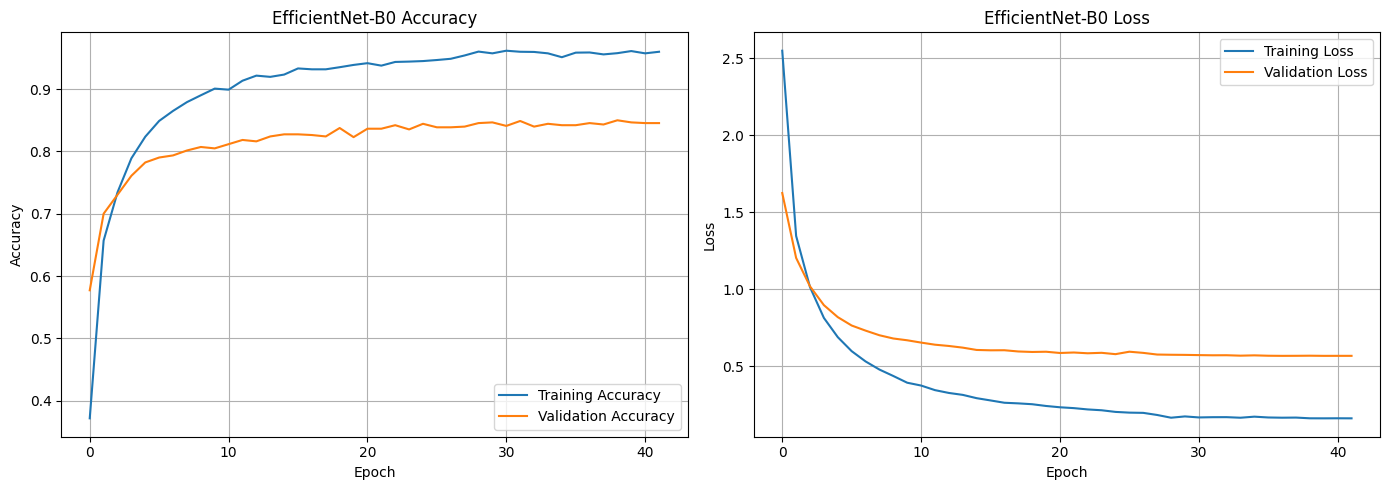

Epochs completed: 42
Best epoch by validation loss: 37
Best validation accuracy: 0.8501
Lowest validation loss: 0.5660


In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("EfficientNet-B0 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("EfficientNet-B0 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

best_epoch = min(
    range(len(history.history["val_loss"])),
    key=lambda i: history.history["val_loss"][i]
) + 1

print("Epochs completed:", len(history.history["loss"]))
print("Best epoch by validation loss:", best_epoch)
print("Best validation accuracy:",
      f"{max(history.history['val_accuracy']):.4f}")
print("Lowest validation loss:",
      f"{min(history.history['val_loss']):.4f}")

In [13]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

MODEL_PATH = (
    "/content/drive/MyDrive/Traffic_Sign_Project/"
    "models/efficientnetb0/efficientnetb0_best.keras"
)

# Load the best checkpoint
efficientnet_model = tf.keras.models.load_model(MODEL_PATH)

# Evaluate test data
test_loss, test_accuracy = efficientnet_model.evaluate(
    test_ds, verbose=1
)

# Get true labels and predictions
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = efficientnet_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Calculate metrics
macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)
weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print("\nEfficientNet-B0 Test Results")
print(f"Test Loss: {test_loss:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall: {macro_recall:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")

41/41 ━━━━━━━━━━━━━━━━━━━━ 28s 297ms/step - accuracy: 0.8269 - loss: 0.7095
41/41 ━━━━━━━━━━━━━━━━━━━━ 16s 242ms/step

EfficientNet-B0 Test Results
Test Loss: 0.7095
Accuracy: 0.8269
Macro Precision: 0.6565
Macro Recall: 0.6448
Macro F1-score: 0.6348
Weighted F1-score: 0.8231


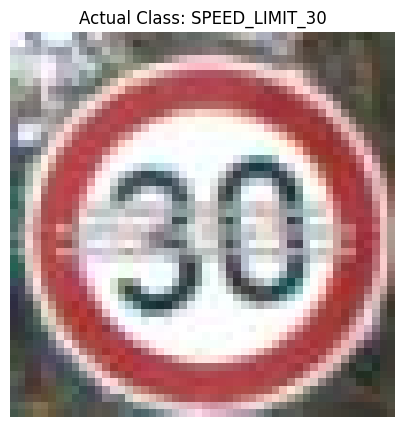

Image: 65160.jpg
Actual class: SPEED_LIMIT_30

Top 3 Predictions:
SPEED_LIMIT_30: 84.43%
SPEED_LIMIT_50: 12.05%
SPEED_LIMIT_60: 1.62%

Predicted class: SPEED_LIMIT_30
Correct prediction: True


In [18]:
import numpy as np
import matplotlib.pyplot as plt
import random
from pathlib import Path
from PIL import Image

# Collect all test images
test_images = [
    p for p in Path(TEST_DIR).rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
]

# Select a random image
image_path = random.choice(test_images)

# Actual class
actual_class = image_path.parent.name

# Load and preprocess image
image = Image.open(image_path).convert("RGB")
image_resized = image.resize((224, 224))
image_array = np.array(image_resized, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)

# Predict
probabilities = efficientnet_model.predict(image_array, verbose=0)[0]
top_indices = np.argsort(probabilities)[::-1][:3]

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(f"Actual Class: {actual_class}")
plt.axis("off")
plt.show()

# Display predictions
print("Image:", image_path.name)
print("Actual class:", actual_class)
print("\nTop 3 Predictions:")

for i in top_indices:
    print(f"{CLASS_NAMES[i]}: {probabilities[i] * 100:.2f}%")

# Check whether top prediction is correct
predicted_class = CLASS_NAMES[top_indices[0]]
print("\nPredicted class:", predicted_class)
print("Correct prediction:", predicted_class == actual_class)

In [19]:
import os
import json
import tensorflow as tf

MODEL_DIR = "/content/drive/MyDrive/Traffic_Sign_Project/models/"
os.makedirs(MODEL_DIR, exist_ok=True)

# 1. Save model
MODEL_PATH = os.path.join(MODEL_DIR, "efficientnetb0_best.keras")
efficientnet_model.save(MODEL_PATH)

# 2. Save class mapping in the exact training order
CLASS_PATH = os.path.join(MODEL_DIR, "class_names_efficientnetb0.json")

with open(CLASS_PATH, "w") as f:
    json.dump(CLASS_NAMES, f, indent=4)

print("Model saved:", MODEL_PATH)
print("Class mapping saved:", CLASS_PATH)
print("Number of classes:", len(CLASS_NAMES))

Model saved: /content/drive/MyDrive/Traffic_Sign_Project/models/efficientnetb0_best.keras
Class mapping saved: /content/drive/MyDrive/Traffic_Sign_Project/models/class_names_efficientnetb0.json
Number of classes: 85
